# TORCH MODEL BASELINES

## Libraries

In [1]:
# https://github.com/creafz/pytorch-cnn-finetune
install_packages = [("cnn-finetune","cnn_finetune"), ("timm","timm"), ("pretrainedmodels", "pretrainedmodels")]
for package_name, lib_name in install_packages:
    try:
        lib = __import__(lib_name)
    except:
        print(f'Install package [{package_name}]...')
        !pip install $package_name 2>&1 >> /dev/null
    pass # for

# fix ssl error in downloading pretrained weight 
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

Install package [cnn-finetune]...
Install package [timm]...


In [1]:
import pprint
from IPython import display

try:
    import timm
    import pretrainedmodels
    from cnn_finetune import make_model
except:
    pass

import torch
import torch.nn as nn
from datetime import datetime

import pandas as pd
import numpy as np

import time, copy, tqdm
import json

In [2]:
import os
import cv2

import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, f1_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import albumentations
from albumentations.pytorch import ToTensorV2

from albumentations import (
    HorizontalFlip, IAAPerspective, ShiftScaleRotate, CLAHE, RandomRotate90,
    Transpose, ShiftScaleRotate, Blur, OpticalDistortion, GridDistortion, HueSaturationValue,
    IAAAdditiveGaussianNoise, GaussNoise, MotionBlur, MedianBlur, IAAPiecewiseAffine,
    IAASharpen, IAAEmboss, RandomContrast, RandomBrightness, Flip, OneOf, Compose, ToFloat, 
    Resize, Normalize, Rotate, RandomCrop, Crop, CenterCrop, DualTransform, PadIfNeeded, RandomCrop, 
    IAAFliplr, IAASuperpixels, VerticalFlip, RandomGamma, ElasticTransform, ImageOnlyTransform, RandomResizedCrop, Affine
)

## Params

In [3]:
app_cfg = {
    "input_dir" : "/kaggle/input", 
    "output_dir": "/kaggle/working",
    "pretrained_dir": "{input_dir}/adler-torch-pretrainedmodels-weights",
    
    "exps_dir"  : "{output_dir}/exps",
    "dataset_cfg": {
        "breast_imgage": {
            "data_root" : "{input_dir}/adler-breast-cancer-image/image_{{size}}",
        },
        "breast_org": {
            "data_root" : "{input_dir}/rsna-breast-cancer-detection",
        },
    },
    
    "models_cfg": {
        "baseline_densenet121_v0": {
            "cls": "breast_baselines_v0",
            "cfg": {
                "model_name": "densenet121", # densenet121, se_resnext50_32x4d    
                "output_classes": 2, 
                "num_classes": 1024, 
                "pretrained": True,
            }
        },
       
        "baseline_se_resnext50_32x4d_v0": {
            "cls": "breast_baselines_v0",
            "cfg": {
                "model_name": "se_resnext50_32x4d", # densenet121, se_resnext50_32x4d    
                "output_classes": 2, 
                "num_classes": 1024, 
                "pretrained": True,
            }
        },
        
        "baseline_se_resnext50_32x4d_v1": {
            "cls": "breast_baselines_v0",
            "cfg": {
                "model_name": "se_resnext50_32x4d", # densenet121, se_resnext50_32x4d    
                "output_classes": 2, 
                "num_classes": 2048, 
                "pretrained": False,
            }
        },
        
        "baseline_resnet50_v0": {
            "cls": "breast_baselines_v0",
            "cfg": {
                "model_name": "resnet50", # densenet121, se_resnext50_32x4d    
                "output_classes": 2, 
                "num_classes": 512,  # 128 (failed)
                "pretrained": False,
            },
            # Normalize() - 'mean': [0.485, 0.456, 0.406],'std': [0.229, 0.224, 0.225],
        },      
        
        "baseline_se_resnext50_32x4d_v2": {
            "cls": "breast_baselines_v0",
            "cfg": {
                "model_name": "se_resnext50_32x4d", # densenet121, se_resnext50_32x4d    
                "output_classes": 2, 
                "num_classes": 2048, 
                "pretrained": True,
            }
        },        
    },
    
    "data_augs_cfg": {
        "crop_v0": {
            "train_aug_cls": "breast_train_aug_crop_v0",
            "valid_aug_cls": "breast_valid_aug_crop_v0",
            "cfg": {
                "scale_size": None,
                "image_size": '{params_cfg["image_size"]}',
                "crop_size" : '{params_cfg["crop_size"]}',
                "eval": ["image_size", "crop_size"],
            },
        },
    }
}

params_debug_cfg = {
    "run_name"    : "test-01",
    "epochs"      : 2,
    "train_nsteps": 2,
    "valid_nsteps": 2,
}

params_cfg = {
    # "run_verbose"  : True, # default False
    
    "run_date"   : "{datetime.now():%y%m%d-%H%M}",
    "run_dir"    : "{exps_dir}/exps-{run_name}",
    "logs_file"  : "{run_dir}/train.log.txt",
    
    # train info
    "gpus": "0, 1",
    "gradient_accumulation_steps": 1,
    # "max_grad_norm": 1000,
    "max_grad_norm": None,

    "run_name"   : "baseline_se_resnext50_32x4d_v2-crop_v0-230105-01",
    "epochs": 1000,
    "train_nsteps": 0,
    "valid_nsteps": 0,
    
    "seed"  : 42,
    
    # model_config
    "model_name" : "baseline_se_resnext50_32x4d_v2",
    "model_weight": None,
    
    # data loader 
    "batch_size": 32,
    
    
    "num_workers": os.cpu_count(),
    "pin_memory": True,
    
    'nfolds': 3,
    
    "data_size" : 256,
    
    "image_size": 224,
    "crop_size" : 256,
    "data_aug" : "crop_v0",
    
    # loss
    "label_smoothing": 0.2,
    
    "early_stopping": 5,
    
    # optim
    "learning_rate": 0.00001,
    "weight_decay" : 0.000001,
    # "weight_decay" : 0.0004,
    "optim_cls": "AdamW",
    
    "rclone_init": False,
    "rclone_check": False,
    "rclone_upload": False,
}
if params_cfg.get("run_verbose", False) is True:
    params_cfg.update(**globals().get("params_debug_cfg", {}))

list_evalf  = [app_cfg, params_cfg]
list_evalf += [*list(app_cfg["dataset_cfg"].values())]
list_evalf += [*list([v["cfg"] for _, v in app_cfg["data_augs_cfg"].items()])]
for cfg in list_evalf:
    for k in cfg:
        try:
            if type(cfg[k]) is str:
                cfg[k] = eval("f'{}'".format(cfg[k]), {**globals(), **app_cfg, **params_cfg, **cfg})
        except:
            pass    
        
    for k in cfg.get('evalf', []):
        try:
            cfg[k] = eval("f'{}'".format(cfg[k]), {**globals(), **app_cfg, **params_cfg, **cfg})
        except:
            pass
    cfg.pop("evalf", [])
        
    for k in cfg.get('eval', []):
        try:
            cfg[k] = eval(cfg[k], {**globals(), **app_cfg, **params_cfg, **cfg})
        except:
            pass
    cfg.pop("eval", [])
    pass # for
      
for name in ["app_cfg", "params_cfg"]:
    print("-"*10, f'{name}', "-"*10)
    for k in globals()[name]:
        print(f'+ {k}: {pprint.pformat(globals()[name][k])}')
    print()

---------- app_cfg ----------
+ input_dir: '/kaggle/input'
+ output_dir: '/kaggle/working'
+ pretrained_dir: '/kaggle/input/adler-torch-pretrainedmodels-weights'
+ exps_dir: '/kaggle/working/exps'
+ dataset_cfg: {'breast_imgage': {'data_root': '/kaggle/input/adler-breast-cancer-image/image_{size}'},
 'breast_org': {'data_root': '/kaggle/input/rsna-breast-cancer-detection'}}
+ models_cfg: {'baseline_densenet121_v0': {'cfg': {'model_name': 'densenet121',
                                     'num_classes': 1024,
                                     'output_classes': 2,
                                     'pretrained': True},
                             'cls': 'breast_baselines_v0'},
 'baseline_resnet50_v0': {'cfg': {'model_name': 'resnet50',
                                  'num_classes': 512,
                                  'output_classes': 2,
                                  'pretrained': False},
                          'cls': 'breast_baselines_v0'},
 'baseline_se_resnext50_32x

In [5]:
os.makedirs(f'{params_cfg["run_dir"]}/data', exist_ok=True)

In [6]:
def seed_everything(seed: int):
    import random, os
    import numpy as np
    import torch
    
    print(f'*** seed_everything ***\n seed:{seed}\n')
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True
    
seed_everything(params_cfg["seed"])

*** seed_everything ***
 seed:42



In [7]:
# pretrained_weights
pretrained_dir = app_cfg['pretrained_dir']

!mkdir -p /root/.cache/torch/hub
![ -d "/root/.cache/torch/hub/checkpoints" ] && rm -r /root/.cache/torch/hub/checkpoints
!ln -s $pretrained_dir /root/.cache/torch/hub/checkpoints
!ls -la /root/.cache/torch/hub/checkpoints
!echo .
!ls -la $pretrained_dir

lrwxrwxrwx 1 root root 50 Jan  5 08:49 /root/.cache/torch/hub/checkpoints -> /kaggle/input/adler-torch-pretrainedmodels-weights
.
total 271284
drwxr-xr-x 2 nobody nogroup         0 Jan  3 08:32 .
drwxr-xr-x 5 root   root         4096 Jan  5 08:48 ..
-rw-r--r-- 1 nobody nogroup  32342954 Jan  3 08:32 densenet121-a639ec97.pth
-rw-r--r-- 1 nobody nogroup  32350226 Jan  3 08:32 densenet121-fbdb23505.pth
-rw-r--r-- 1 nobody nogroup 102530333 Jan  3 08:33 resnet50-0676ba61.pth
-rw-r--r-- 1 nobody nogroup 110559176 Jan  3 08:33 se_resnext50_32x4d-a260b3a4.pth


In [8]:
def init_logger(log_file):
    import os, sys
    from logging import getLogger, INFO, FileHandler,  Formatter,  StreamHandler
    
    os.makedirs(os.path.dirname(log_file), exist_ok=True)
    
    logger = getLogger(__name__)
    logger.setLevel(INFO)
    
    handler1 = StreamHandler(sys.stdout)
    handler1.setFormatter(Formatter("%(message)s"))
    
    handler2 = FileHandler(filename=log_file)
    handler2.setFormatter(Formatter("%(message)s"))
    
    logger.handlers.clear()
    logger.addHandler(handler1)
    logger.addHandler(handler2)
    return logger


logger = init_logger(params_cfg["logs_file"])

## Exploratory data analysis (EDA)

In [9]:
train_file = f'{app_cfg["dataset_cfg"]["breast_org"]["data_root"]}/train.csv'
test_file = f'{app_cfg["dataset_cfg"]["breast_org"]["data_root"]}/test.csv'

df_train = pd.read_csv(train_file)
df_test = pd.read_csv(test_file)

In [10]:
print("-"*10, "test_info", "-"*10)
display.display(df_test.iloc[0])
print()

print("-"*10, "train_info", "-"*10)
display.display(df_train.iloc[0])
print()

---------- test_info ----------


site_id                  2
patient_id           10008
image_id         736471439
laterality               L
view                   MLO
age                     81
implant                  0
machine_id              21
prediction_id      10008_L
Name: 0, dtype: object


---------- train_info ----------


site_id                            2
patient_id                     10006
image_id                   462822612
laterality                         L
view                              CC
age                             61.0
cancer                             0
biopsy                             0
invasive                           0
BIRADS                           NaN
implant                            0
density                          NaN
machine_id                        29
difficult_negative_case        False
Name: 0, dtype: object

In [11]:
print("Cancer/NoCancer Images: ", np.unique(df_train['cancer'], return_counts = True))

Cancer/NoCancer Images:  (array([0, 1]), array([53548,  1158]))


In [12]:
df_info = df_train.groupby(["patient_id", "laterality"], group_keys = False).agg(
    image_id = pd.NamedAgg(column="image_id", aggfunc=lambda x: list(x)),
    view = pd.NamedAgg(column="view", aggfunc=lambda x: list(x)),
    age = pd.NamedAgg(column="age", aggfunc=lambda x: list(x)[0]),    
    implant = pd.NamedAgg(column="implant", aggfunc=lambda x: list(x)[0]),
    cancer = pd.NamedAgg(column="cancer", aggfunc=lambda x: list(x)[0]),
    
    view_cnt = pd.NamedAgg(column="view", aggfunc=lambda x: len(x)),
    image_cnt = pd.NamedAgg(column="image_id", aggfunc=lambda x: len(x)),
    
    image_uni = pd.NamedAgg(column="image_id", aggfunc=lambda x: len(np.unique(x))),
    cancer_uni = pd.NamedAgg(column="cancer", aggfunc=lambda x: len(np.unique(x))),
    age_uni = pd.NamedAgg(column="age", aggfunc=lambda x: len(np.unique(x))),
    implant_uni = pd.NamedAgg(column="implant", aggfunc=lambda x: len(np.unique(x))),
    view_uni = pd.NamedAgg(column="view", aggfunc=lambda x: len(np.unique(x))),
).sort_values(["patient_id", "laterality"]).reset_index()

df_info.insert(0, "prediction_id", df_info[["patient_id", "laterality"]].apply(lambda x: "_".join([str(v) for v in x]), axis = 1))

display.display(df_info)

,prediction_id,patient_id,laterality,image_id,view,age,implant,cancer,view_cnt,image_cnt,image_uni,cancer_uni,age_uni,implant_uni,view_uni
0,5_L,5,L,"[640805896, 1351088028]","[MLO, CC]",68.0,0,0,2,2,2,1,1,1,2
1,5_R,5,R,"[940388076, 1633417959]","[CC, MLO]",68.0,0,0,2,2,2,1,1,1,2
2,25_L,25,L,"[1442180348, 1789648218]","[MLO, CC]",62.0,0,0,2,2,2,1,1,1,2
3,25_R,25,R,"[822390278, 1723979573, 1962456803, 1997933901]","[CC, MLO, MLO, CC]",62.0,0,0,4,4,4,1,1,1,2
4,28_L,28,L,"[825270681, 1113093954]","[CC, MLO]",40.0,0,0,2,2,2,1,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23821,65526_R,65526,R,"[1334665125, 1863656225]","[MLO, CC]",62.0,0,0,2,2,2,1,1,1,2
23822,65530_L,65530,L,"[633167749, 1277826488, 1627492472]","[MLO, CC, MLO]",48.0,0,0,3,3,3,1,1,1,2
23823,65530_R,65530,R,"[675828643, 1039644878, 1401303823]","[MLO, CC, MLO]",48.0,0,0,3,3,3,1,1,1,2
23824,65534_L,65534,L,"[1436834199, 1888933323]","[CC, MLO]",46.0,0,0,2,2,2,1,1,1,2


In [13]:
print("-"*10, "unique", "-"*10)
for v in df_info.columns:
    if v.endswith("_uni"):
        print(f'{v}: {np.unique(df_info[v], return_counts=True)}')
print()    
    
print("-"*10, "count", "-"*10)
for v in df_info.columns:
    if v.endswith("_cnt"):
        print(f'{v}: {np.unique(df_info[v], return_counts=True)}')

print("-"*10, "attributes", "-"*10)
for v in ["age", "implant", "cancer"]:
    print(f"{v}:\n--> ", pprint.pformat(np.unique(df_info[v], return_counts=True), indent=0))

---------- unique ----------
image_uni: (array([2, 3, 4, 5, 6, 7, 8]), array([18384,  4227,   904,   239,    60,    10,     2]))
cancer_uni: (array([1]), array([23826]))
age_uni: (array([1]), array([23826]))
implant_uni: (array([1]), array([23826]))
view_uni: (array([2, 3]), array([23790,    36]))

---------- count ----------
view_cnt: (array([2, 3, 4, 5, 6, 7, 8]), array([18384,  4227,   904,   239,    60,    10,     2]))
image_cnt: (array([2, 3, 4, 5, 6, 7, 8]), array([18384,  4227,   904,   239,    60,    10,     2]))
---------- attributes ----------
age:
-->  (array([26., 28., 29., 30., 31., 32., 33., 34., 35., 36., 37., 38., 39.,
       40., 41., 42., 43., 44., 45., 46., 47., 48., 49., 50., 51., 52.,
       53., 54., 55., 56., 57., 58., 59., 60., 61., 62., 63., 64., 65.,
       66., 67., 68., 69., 70., 71., 72., 73., 74., 75., 76., 77., 78.,
       79., 80., 81., 82., 83., 84., 85., 86., 87., 88., 89., nan]),
array([   4,    8,    2,    2,    2,    6,    4,    8,   18,   22,   38,

## Datasets

### Load Data

In [14]:
image_root = app_cfg["dataset_cfg"]["breast_imgage"]["data_root"].format(size = params_cfg["data_size"])

column_names = ["patient_id", "laterality", "image_id", "cancer", "view"]

df_data = pd.DataFrame(dtype=object)

df_data["prediction_id"] = df_train[column_names].apply(lambda x: "_".join([str(x[k]) for k in ["patient_id", "laterality"]]), axis = 1)
df_data["image_path"] = df_train[column_names].apply(lambda x: f'{image_root}/{x["patient_id"]}_{x["image_id"]}.png', axis = 1)
df_data["image_view"] = df_train[column_names].apply(lambda x: str(x["view"]), axis = 1)
df_data["output"] = df_train[column_names].apply(lambda x: int(x["cancer"]), axis = 1)

df_data = df_data.sort_values(["prediction_id", "image_path"], ignore_index = True)

logger.info(f'Class Distribution: {np.unique(df_data["output"], return_counts=True)}')
display.display(df_data)

Class Distribution: (array([0, 1]), array([53548,  1158]))


,prediction_id,image_path,image_view,output
0,10006_L,/kaggle/input/adler-breast-cancer-image/image_...,MLO,0
1,10006_L,/kaggle/input/adler-breast-cancer-image/image_...,CC,0
2,10006_R,/kaggle/input/adler-breast-cancer-image/image_...,MLO,0
3,10006_R,/kaggle/input/adler-breast-cancer-image/image_...,CC,0
4,10011_L,/kaggle/input/adler-breast-cancer-image/image_...,CC,0
...,...,...,...,...
54701,997_R,/kaggle/input/adler-breast-cancer-image/image_...,MLO,0
54702,9989_L,/kaggle/input/adler-breast-cancer-image/image_...,CC,0
54703,9989_L,/kaggle/input/adler-breast-cancer-image/image_...,MLO,0
54704,9989_R,/kaggle/input/adler-breast-cancer-image/image_...,MLO,0


### Data Cross-Validation

In [15]:
from sklearn.model_selection import StratifiedGroupKFold

kfold_cls = StratifiedGroupKFold(n_splits=params_cfg["nfolds"], random_state=params_cfg["seed"], shuffle=True)
kfold_cfg = {}
for fold, (train_index, test_index) in enumerate(kfold_cls.split(np.arange(len(df_data)), df_data["output"], df_data["prediction_id"])):
    cfg = {}
    cfg["train_index"] = train_index
    cfg["test_index"]  = test_index
    kfold_cfg[f'fold{fold}'] = cfg

In [16]:
for i in range(params_cfg["nfolds"]):
    logger.info(f'{"-"*10} fold{i} {"-"*10}')
    logger.info(f'{np.unique(df_data.iloc[kfold_cfg[f"fold{i}"]["train_index"]]["output"], return_counts=True)}')
    logger.info(f'{np.unique(df_data.iloc[kfold_cfg[f"fold{i}"]["test_index"]]["output"], return_counts=True)}')
    logger.info("")

---------- fold0 ----------
(array([0, 1]), array([35623,   790]))
(array([0, 1]), array([17925,   368]))

---------- fold1 ----------
(array([0, 1]), array([35827,   735]))
(array([0, 1]), array([17721,   423]))

---------- fold2 ----------
(array([0, 1]), array([35646,   791]))
(array([0, 1]), array([17902,   367]))



### Augmentations

In [17]:
def undesired_objects (image,
                       opening_size = (50, 50), 
                       min_size = 400,
                       verbose=False):
    """
    cv2.MORPH_RECT, cv2.MORPH_ELLIPSE, cv2.MORPH_CROSS
    """
    import cv2
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, opening_size)
    
    image_ = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    
    image_ = cv2.GaussianBlur(image_, (7, 7), 0)
    _, image_ = cv2.threshold(image_, 0, 255,cv2.THRESH_BINARY | cv2.THRESH_OTSU)
    
    thresh_ = cv2.dilate(image_, kernel, iterations=1)
    thresh_ = cv2.erode(thresh_, kernel, iterations=1)

    contours, hierarchy = cv2.findContours(thresh_, cv2.RETR_TREE , cv2.CHAIN_APPROX_TC89_L1 )
    thresh_ = np.zeros_like(thresh_, np.uint8)
    for i in range(len(contours)):
        cv2.drawContours(thresh_, [contours[i]], -1, 255, -1)
        
    output = cv2.connectedComponentsWithStatsWithAlgorithm(thresh_, 8, cv2.CV_32S, cv2.CCL_SPAGHETTI)
    (numLabels, labels, stats, centroids) = output
    thresh_ = np.zeros_like(image_, np.uint8)
    for i in range(1, numLabels):
        if stats[i, -1]>=min_size:
            thresh_[labels == i] = 255
        
    thresh_ = cv2.dilate(thresh_, kernel, iterations=1)
    thresh_ = cv2.erode(thresh_, kernel, iterations=1)
    
    left, top, width, height = cv2.boundingRect(thresh_)
    if width<=10 or height<=10:
        left, top, width, height = 0, 0, thresh_.shape[1], thresh_.shape[0]
    image1 = image[top: top+height, left:left+width]
    
    if verbose:
        plt.subplot(2,2,1), plt.imshow(image)
        plt.subplot(2,2,2), plt.imshow(image_)
        plt.subplot(2,2,3), plt.imshow(thresh_)
        plt.subplot(2,2,4), plt.imshow((image1).astype(np.uint8))
        plt.show()
    return image1
    
class GetLargestComponent(ImageOnlyTransform):
    """
    https://www.kaggle.com/code/hirotaka0122/bengali-custom-albumentations-transforms
    """
    def __init__(self, min_size=400, opening_size = (50,50), verbose=False, always_apply=False, p=0.5):
        super(GetLargestComponent, self).__init__(always_apply, p)
        self.verbose = verbose
        self.min_size = min_size
        self.opening_size = opening_size
        
    def apply(self, img, **params):
        return undesired_objects(img, verbose=self.verbose, 
                                 min_size=self.min_size, 
                                 opening_size = self.opening_size)
    
    def get_transform_init_args_names(self):
        return ("verbose", "min_size", "opening_size", )

    
def breast_train_aug_v1(image_size = 224, scale_size = None, p=1.0):
    return Compose([
        Resize(image_size, image_size, p = 1),
    ], p=p)
    pass # breast_train_aug_v0

def breast_train_aug_v0(image_size = 224, scale_size = None, p=1.0):
    fn_none = lambda x: [v for v in [x] if v is not None]
    return Compose([
        *fn_none(Resize(scale_size, scale_size, p=1) if scale_size is not None else None),
        RandomCrop(image_size, image_size, p = 1),
        Rotate(limit = 5),
        HorizontalFlip(p=0.5),
        # Affine(shear=(-10, 10), p = 0.5), # fixing
        # ToFloat(max_value  = 255.0),
#         OneOf([
#             OneOf([
#                 RandomResizedCrop(limit=0.125),
#                 # HorizontalShear(origin_img_size, np.random.uniform(-0.07,0.07)),
#                 ShiftScaleRotateHeng(dx=0, dy=0, scale=1, angle=np.random.uniform(0, 10)),
#                 ElasticTransformHeng(grid=10, distort=np.random.uniform(0, 0.15)),
#             ]),
#             OneOf([
#                 BrightnessShift(np.random.uniform(-0.05, 0.05)),
#                 BrightnessMultiply(np.random.uniform(1-0.05, 1+0.05)),
#                 DoGama(np.random.uniform(1-0.05, 1+0.05)),
#             ])
#         ]),
        PadIfNeeded(min_height=image_size, min_width=image_size, p=1),
#        Normalize(mean=0.5, std=0.5, max_pixel_value = 1.0),
    ], p=p)
    pass # breast_train_aug_v0

def breast_valid_aug_v0(image_size=224, scale_size = None):
    return Compose([
        # CenterCrop(image_size, image_size),
        Resize(image_size, image_size)
        # Normalize(),
    ], p=1)
    pass # breast_valid_aug_v0

def breast_train_aug_crop_v0(image_size = 224, crop_size = 256, scale_size = None, p=1.0):
    return Compose([
        GetLargestComponent(p=1),
        # PadIfNeeded(min_height=image_size, min_width=image_size, p=1),
        Resize(crop_size, crop_size),
        RandomCrop(image_size, image_size, p = 1),
        Rotate(limit = 5),
        HorizontalFlip(p=0.5),
        # Affine(shear=(-10, 10), p = 0.5), # fixing
        # ToFloat(max_value  = 255.0),
#         OneOf([
#             OneOf([
#                 RandomResizedCrop(limit=0.125),
#                 # HorizontalShear(origin_img_size, np.random.uniform(-0.07,0.07)),
#                 ShiftScaleRotateHeng(dx=0, dy=0, scale=1, angle=np.random.uniform(0, 10)),
#                 ElasticTransformHeng(grid=10, distort=np.random.uniform(0, 0.15)),
#             ]),
#             OneOf([
#                 BrightnessShift(np.random.uniform(-0.05, 0.05)),
#                 BrightnessMultiply(np.random.uniform(1-0.05, 1+0.05)),
#                 DoGama(np.random.uniform(1-0.05, 1+0.05)),
#             ])
#         ]),
        PadIfNeeded(min_height=image_size, min_width=image_size, 
                    border_mode = cv2.BORDER_CONSTANT, value = 0, p=1),
#        Normalize(mean=0.5, std=0.5, max_pixel_value = 1.0),
    ], p=p)
    pass # breast_train_aug_v0

def breast_valid_aug_crop_v0(image_size=224, crop_size = 256, scale_size = None, p = 1):
    return Compose([
        GetLargestComponent(p=1),
        # CenterCrop(image_size, image_size),
        Resize(image_size, image_size),
        # Normalize(),
    ], p=1)
    pass # breast_valid_aug_crop_v0

breast_train_aug = eval(app_cfg["data_augs_cfg"][params_cfg["data_aug"]]["train_aug_cls"])
breast_valid_aug = eval(app_cfg["data_augs_cfg"][params_cfg["data_aug"]]["valid_aug_cls"])
breast_aug_cfg = app_cfg["data_augs_cfg"][params_cfg["data_aug"]]["cfg"]

logger.info(f'{"-"*10} data_aug {"-"*10}')
logger.info(f'{breast_aug_cfg}')
logger.info(f'{breast_train_aug}')
logger.info(f'{breast_valid_aug}')

# train_data.transforms = None
# for i in range(32):
#     image, _ = train_data[i] # 6, 10
#     plt.figure(figsize=(10,10))
#     plt.subplot(1,2,1), plt.imshow(image)
#     plt.subplot(1,2,2), plt.imshow(undesired_objects(image.copy(), verbose=True))
#     plt.show()

---------- data_aug ----------
{'scale_size': None, 'image_size': 224, 'crop_size': 256}
<function breast_train_aug_crop_v0 at 0x7f188e68de60>
<function breast_valid_aug_crop_v0 at 0x7f188e68df80>


### Datasets

In [18]:
class RSNADataset(Dataset):
    def __init__(self, df_data, train=True, transforms=None, capacity = None, verbose = True):
        """
        df_data: 
        + prediction_id  : 10006_L
        + image_path     : /kaggle/input/adler-breast-cancer-image/image_256/10006_1459541791.png
        + image_view     : MLO
        + output         : 0
        """
        self.df_data = df_data
        self.is_train = train
        self.transforms = transforms
        self.verbose = verbose
        
        self.label_info = {
            0: list(self.df_data[self.df_data["output"]==0].index),
            1: list(self.df_data[self.df_data["output"]==1].index),
        }
        self.n_labels = [len(self.label_info[v]) for v in self.label_info]
        self.capacity = capacity if capacity is not None else max(self.n_labels)*len(self.n_labels) # len(self.df_data)
        
        pass
    
    def __len__(self):
        return self.capacity
    
    def __getitem__(self, idx):
        idlabel = idx%2
        idxn = (idx // 2) % self.n_labels[idlabel]
        row_info = self.df_data.loc[self.label_info[idlabel][idxn]]
        # image = cv2.imread(row_info["image_path"], cv2.IMREAD_GRAYSCALE)
        image = cv2.imread(row_info["image_path"])
        
        if self.transforms:
            image = self.transforms(image=image)["image"]
        
        label = -1
        if self.is_train:
            label = row_info["output"]
        
        if self.verbose:
            print("-"*10, f"data at idx={idx} -> idlabel={idlabel}, idxn={idxn}", "-"*10)
            print('+ row_info')
            display.display(row_info)
            print()
            print(f'Input: {image.shape}, output: {label}')
            plt.imshow(image, cmap = "gray")
            plt.title(f'{os.path.basename(row_info["image_path"])} - {image.shape}')
            plt.show()
            
        return image, label

### Debug

---------- train_data ----------
Len: 71246 [35623, 790]
---------- data at idx=0 -> idlabel=0, idxn=0 ----------
+ row_info


prediction_id                                              10006_L
image_path       /kaggle/input/adler-breast-cancer-image/image_...
image_view                                                     MLO
output                                                           0
Name: 0, dtype: object


Input: (277, 256, 3), output: 0


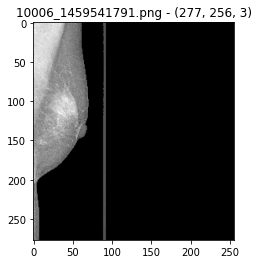


---------- aug ----------


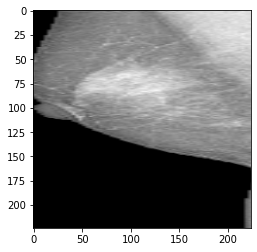

<Figure size 432x288 with 0 Axes>

In [19]:
logger.info(f'{"-"*10} train_data {"-"*10}')
train_data = RSNADataset(df_data.loc[kfold_cfg['fold0']['train_index']])
train_data.transforms = None
logger.info(f'Len: {len(train_data)} {train_data.n_labels}')
train_data[0];
logger.info("")

logger.info(f'{"-"*10} aug {"-"*10}')
train_data.verbose = False
train_data.transforms = breast_train_aug(**breast_aug_cfg)
image, label = train_data[0] # 1001
plt.imshow(image, cmap = 'gray'), plt.show()
plt.savefig(f'{params_cfg["run_dir"]}/data/train_aug.pdf', bbox_inches="tight")
logger.info("")

(<AxesSubplot:>, <matplotlib.image.AxesImage at 0x7f188afe9c10>)

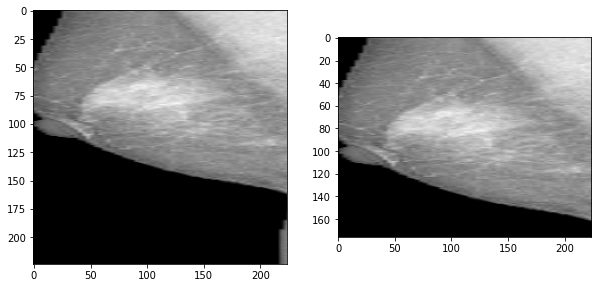

In [20]:
plt.figure(figsize=(10,10))
plt.subplot(1,2,1), plt.imshow(image)
plt.subplot(1,2,2), plt.imshow(GetLargestComponent()(image=image)["image"])

---------- valid_data ----------
Len: 35850 [17925, 368]
---------- data at idx=0 -> idlabel=0, idxn=0 ----------
+ row_info


prediction_id                                              10038_R
image_path       /kaggle/input/adler-breast-cancer-image/image_...
image_view                                                      CC
output                                                           0
Name: 14, dtype: object


Input: (305, 256, 3), output: 0


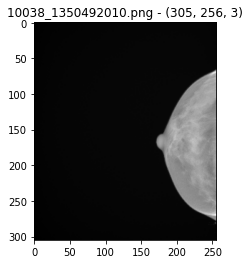


---------- valid_aug ----------


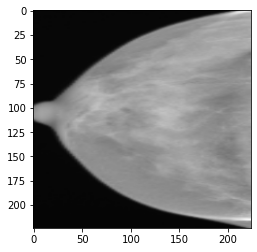

In [21]:
logger.info(f'{"-"*10} valid_data {"-"*10}')
valid_data = RSNADataset(df_data.loc[kfold_cfg['fold0']['test_index']])
valid_data.transforms = None
logger.info(f'Len: {len(valid_data)} {valid_data.n_labels}')
valid_data[0];
logger.info("")

logger.info(f'{"-"*10} valid_aug {"-"*10}')
valid_data.verbose = False
valid_data.transforms =breast_valid_aug(**breast_aug_cfg)
image, label = valid_data[0]
plt.imshow(image, cmap = 'gray')
plt.savefig(f'{params_cfg["run_dir"]}/data/valid_aug.pdf', bbox_inches="tight")
plt.show()
logger.info("")

---------- train_loader ----------
Compose([
  GetLargestComponent(always_apply=False, p=1, verbose=False, min_size=400, opening_size=(50, 50)),
  Resize(always_apply=False, p=1, height=256, width=256, interpolation=1),
  RandomCrop(always_apply=False, p=1, height=224, width=224),
  Rotate(always_apply=False, p=0.5, limit=(-5, 5), interpolation=1, border_mode=4, value=None, mask_value=None, rotate_method='largest_box', crop_border=False),
  HorizontalFlip(always_apply=False, p=0.5),
  PadIfNeeded(always_apply=False, p=1, min_height=224, min_width=224, pad_height_divisor=None, pad_width_divisor=None, border_mode=0, value=0, mask_value=None),
  ToTensorV2(always_apply=True, p=1.0, transpose_mask=False),
], p=1.0, bbox_params=None, keypoint_params=None, additional_targets={})

---------- valid_loader ----------
Compose([
  GetLargestComponent(always_apply=False, p=1, verbose=False, min_size=400, opening_size=(50, 50)),
  Resize(always_apply=False, p=1, height=224, width=224, interpolation

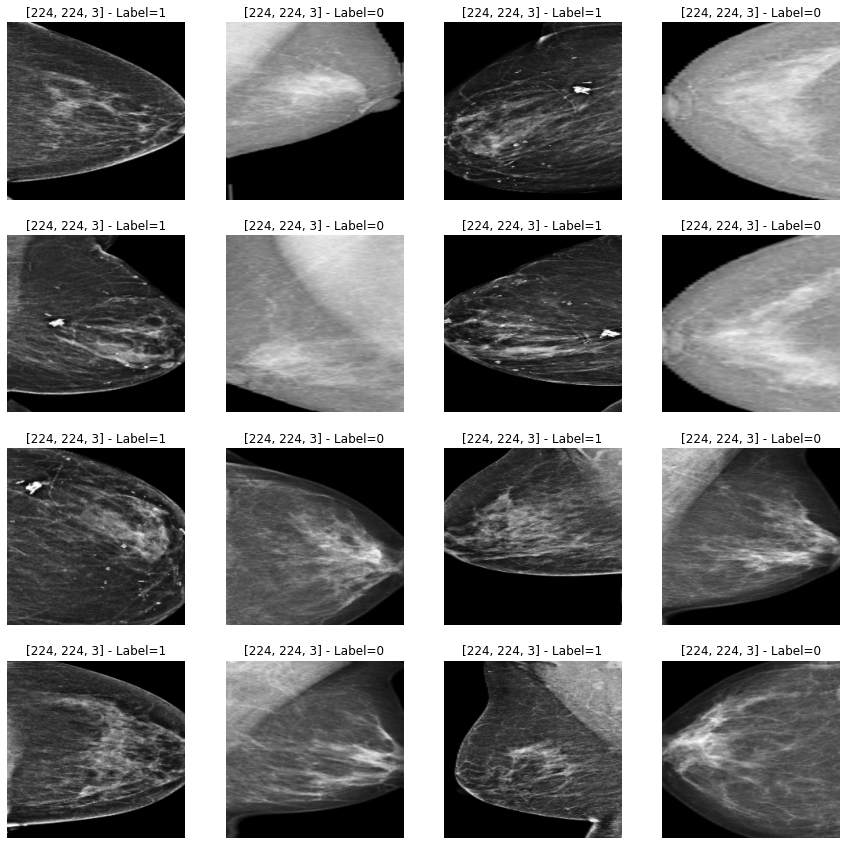

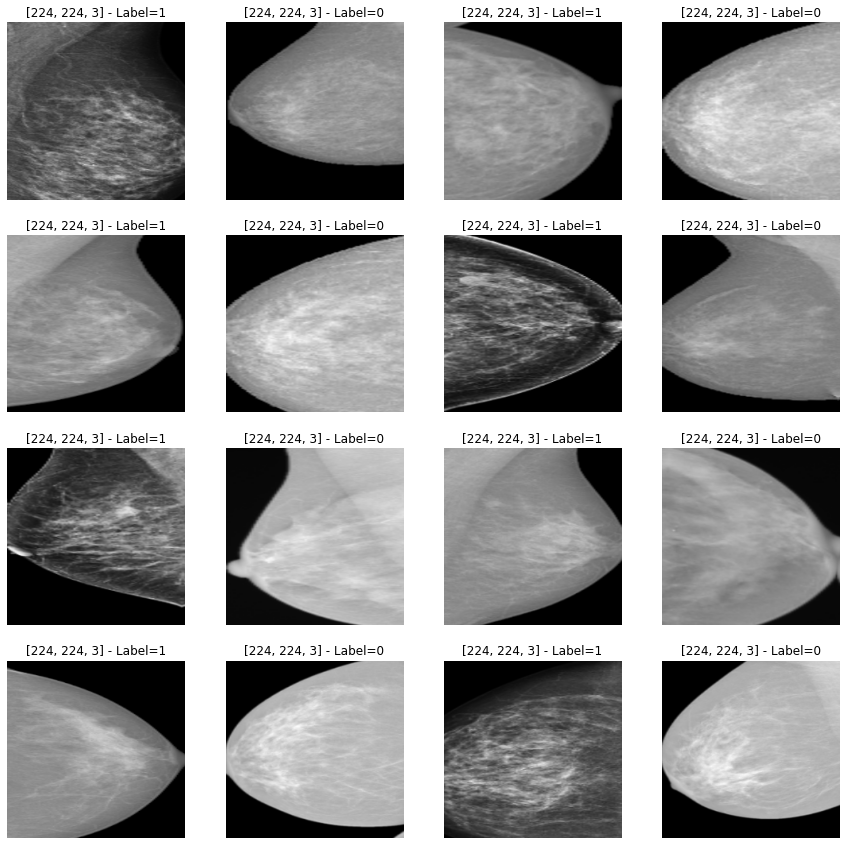


X: shape=[32, 3, 224, 224] - min = 0 - max = 254
y: [0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1]



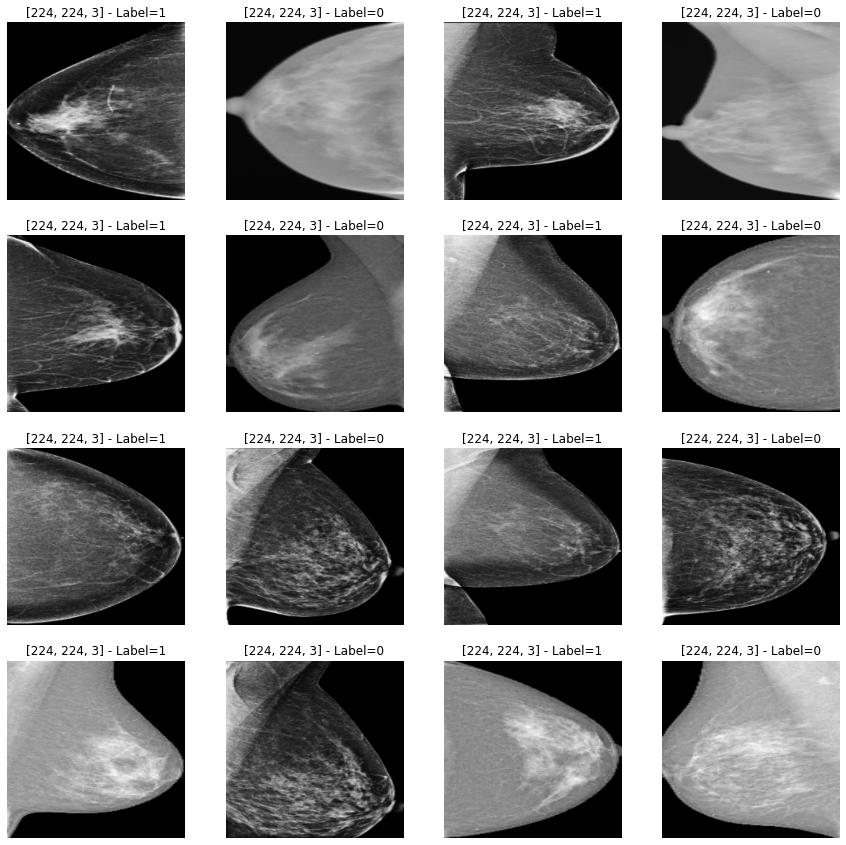

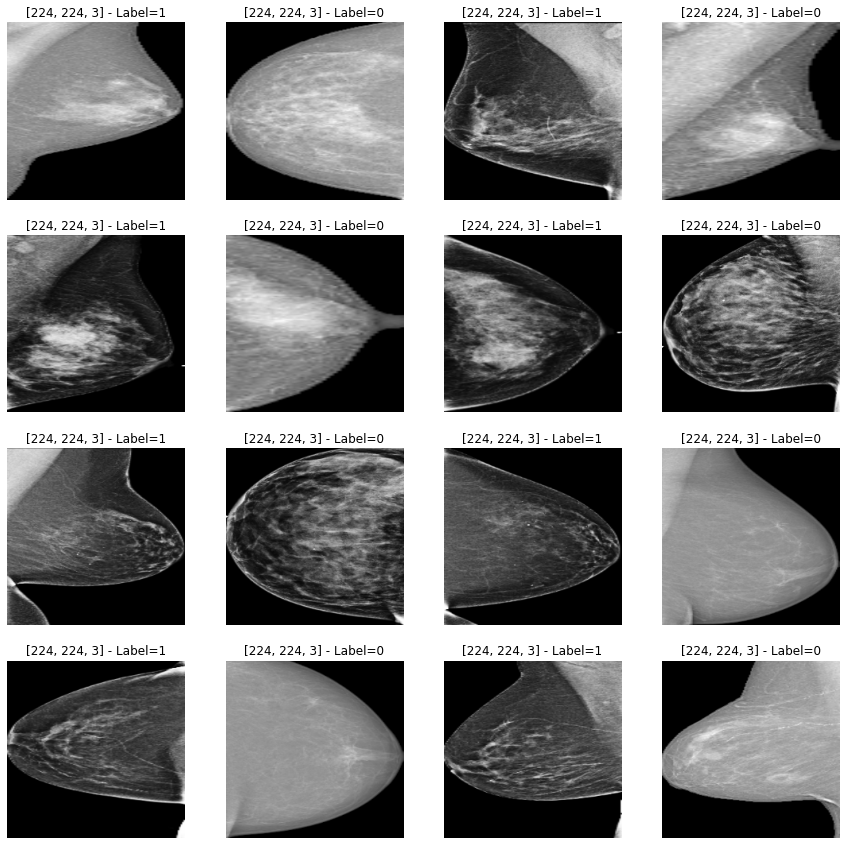

In [22]:
logger.info(f'{"-"*10} train_loader {"-"*10}')
train_data.verbose = False
train_data.transforms = breast_train_aug(**breast_aug_cfg)
train_data.transforms.transforms.append(ToTensorV2())
train_loader = DataLoader(train_data, batch_size=32, shuffle=False)

logger.info(f'{train_data.transforms}')
logger.info("")

logger.info(f'{"-"*10} valid_loader {"-"*10}')
valid_data.verbose = False
valid_data.transforms = breast_valid_aug(**breast_aug_cfg)
valid_data.transforms.transforms.append(ToTensorV2())

valid_loader = DataLoader(valid_data, batch_size=32, shuffle=False)

logger.info(valid_data.transforms)
logger.info("")


logger.info(f'{"-"*10} view_loader {"-"*10}')
for X, y in [next(iter(train_loader)), next(iter(valid_loader))]:
    logger.info(f'X: shape={list(X.shape)} - min = {torch.min(X)} - max = {torch.max(X)}')
    logger.info(f'y: {[int(v) for v in y]}')
    logger.info("")

    X = torch.permute(X, [0, 2, 3, 1])
    for idx in range(len(X)):
        if (idx+1)%16 == 1:
            plt.figure(figsize=(15, 15))
        plt.subplot(4, 4, (idx+1)%16+1), plt.imshow(X[idx, :, :, :], cmap="gray"), plt.axis("off"), plt.title(f'{list(X[idx, :, :, :].shape)} - Label={y[idx].numpy()}')
        if (idx+1)%16==0:
            plt.show()
    logger.info("")

In [23]:
# train_loader = DataLoader(train_data, batch_size=32, shuffle=False)
# for step, (X, y) in tqdm.tqdm(enumerate(train_loader), desc="Train", total=len(train_loader), position=0,leave=True):
#     pass
# train_data = RSNADataset(df_train, train=True, transforms=train_aug, capacity = None, verbose = False)


In [24]:
# valid_data = RSNADataset(df_data.loc[kfold_cfg['fold0']['test_index']].iloc[::-1], 
#                          train=True, 
#                          transforms=breast_valid_aug(**breast_aug_cfg), 
#                          capacity = None, verbose = False)
# # valid_loader = DataLoader(valid_data, batch_size=32, shuffle=False) 
# for step, (X, y) in tqdm.tqdm(enumerate(valid_data), desc="Valid", total=len(valid_data), position=0,leave=True):
#     pass

In [25]:
# valid_data.verbose=True
# valid_data.transforms=None
# X, y = valid_data[1054]

In [26]:
# df_all_train = pd.read_csv(train_file)
# row_info = df_all_train.query('patient_id==822 and image_id==1942326353').iloc[0]
# row_info = valid_data.df_data.loc[valid_data.label_info[0][527]]
# row_info = df_data.loc[53068]

# mask = plt.imread(row_info["image_path"]).astype(np.uint8)
# np.unique(mask)

# dcm_path = f'/kaggle/input/rsna-breast-cancer-detection/train_images/822/1942326353.dcm'

# import SimpleITK as sitk
# dcm_image = sitk.ReadImage(dcm_path, sitk.sitkFloat32)
# dcm_image_data = sitk.GetArrayFromImage(dcm_image)
# np.unique(dcm_image_data)
# plt.imshow(dcm_image_data[0,:,:], cmap='gray')

## Model

### Baselines

In [27]:
def breast_baselines_v0(model_name='densenet121', 
                        pretrained = True, 
                        num_classes=1024, output_classes = 2, 
                        weight=None, n_channels = 3, **kwargs):
    """
    model_name: se_resnext50_32x4d, se_resnext50_32x4d
    """
    opt_model_cfg = {
        "model_name": model_name,
        "num_classes": num_classes,            
        "pretrained": pretrained,
    }
    model = make_model(**opt_model_cfg)
    
    if getattr(model._features[0], "conv1", None) is not None:
        conv1 = model._features[0].conv1
        model._features[0].conv1 = nn.Conv2d(in_channels=n_channels, 
                                             out_channels=conv1.out_channels,
                                             kernel_size=conv1.kernel_size,
                                             stride=conv1.stride,
                                             padding=conv1.padding,
                                             bias=conv1.bias)

        # copy pretrained weights
        model._features[0].conv1.weight.data[:,:3,:,:] = conv1.weight.data
        model._features[0].conv1.weight.data[:,3:n_channels,:,:] = conv1.weight.data[:,:int(n_channels-3),:,:]    
    else:
        conv1 = model._features[0]
        model._features[0] = nn.Conv2d(in_channels=n_channels, 
                                       out_channels=conv1.out_channels,
                                       kernel_size=conv1.kernel_size,
                                       stride=conv1.stride,
                                       padding=conv1.padding,
                                       bias=conv1.bias)

        # copy pretrained weights
        model._features[0].weight.data[:,:3,:,:] = conv1.weight.data
        model._features[0].weight.data[:,3:n_channels,:,:] = conv1.weight.data[:,:int(n_channels-3),:,:]    
    
    # load weight
    if weight:
        model_state_dict = torch.load(weight)['model_state_dict']
        model.load_state_dict(model_state_dict)
        
        print("=" * 10, "Loaded Checkpoint", "="*10)
        print(f"+ Weight Path: {weight}")
        print()
    
    # classifier
    in_features = model._classifier.in_features
    model._classifier = nn.Sequential(
        nn.Linear(
            in_features=in_features, out_features=output_classes
        ),
        nn.Softmax(dim=1)
    )
    
    if kwargs.get("global_scope"):
        kwargs.get("global_scope", {}).update(**locals())
        
    return model

In [28]:
logger.info(f'{"="*10} model_cfg {"="*10}')
model_cls = eval(app_cfg["models_cfg"][params_cfg["model_name"]]["cls"])
model_cfg = app_cfg["models_cfg"][params_cfg["model_name"]]["cfg"]
logger.info(model_cls)
logger.info(model_cfg)
logger.info("")

logger.info(f'{"="*10} model_settings {"="*10}')
for model_name in ["densenet121", "se_resnext50_32x4d", model_cfg["model_name"]]:
    logger.info(f'+ {model_name}:\n{pprint.pformat(pretrainedmodels.pretrained_settings[model_name])}\n')

========== model_cfg ==========
<function breast_baselines_v0 at 0x7f1883cfedd0>
{'model_name': 'se_resnext50_32x4d', 'output_classes': 2, 'num_classes': 2048, 'pretrained': True}

========== model_settings ==========
+ densenet121:
{'imagenet': {'input_range': [0, 1],
              'input_size': [3, 224, 224],
              'input_space': 'RGB',
              'mean': [0.485, 0.456, 0.406],
              'num_classes': 1000,
              'std': [0.229, 0.224, 0.225],
              'url': 'http://data.lip6.fr/cadene/pretrainedmodels/densenet121-fbdb23505.pth'}}

+ se_resnext50_32x4d:
{'imagenet': {'input_range': [0, 1],
              'input_size': [3, 224, 224],
              'input_space': 'RGB',
              'mean': [0.485, 0.456, 0.406],
              'num_classes': 1000,
              'std': [0.229, 0.224, 0.225],
              'url': 'http://data.lip6.fr/cadene/pretrainedmodels/se_resnext50_32x4d-a260b3a4.pth'}}

+ se_resnext50_32x4d:
{'imagenet': {'input_range': [0, 1],
        

In [29]:
!ls /root/.cache/torch/hub/checkpoints

densenet121-a639ec97.pth   resnet50-0676ba61.pth
densenet121-fbdb23505.pth  se_resnext50_32x4d-a260b3a4.pth


In [30]:
model = model_cls(**{**model_cfg, "weight": params_cfg["model_weight"], "global_scope": globals()})

In [31]:
import warnings
warnings.filterwarnings("ignore")

train_data.verbose = False
train_data.transforms = breast_valid_aug(**breast_aug_cfg)
if getattr(model, "original_model_info") is not None:
    train_data.transforms.transforms.append(Normalize(mean = model.original_model_info.mean, std = model.original_model_info.std))
else:
    train_data.transforms.transforms.append(Normalize())
train_data.transforms.transforms.append(ToTensorV2())
train_loader = DataLoader(train_data, batch_size=16, shuffle=True)

logger.info(train_data.transforms)
logger.info("")

X, y = next(iter(train_loader))
y_pred = model(X)
logger.info(f'X: shape={X.shape}, dtype={X.dtype} [{torch.min(X)}, {torch.max(X)}]')
logger.info(f'y: shape={y.shape}, dtype={y.dtype} - {torch.unique(y, return_counts=True)}')
logger.info(f'y_pred: shape={y_pred.shape}, dtype={y_pred.dtype} - {y_pred[0]}')

Compose([
  GetLargestComponent(always_apply=False, p=1, verbose=False, min_size=400, opening_size=(50, 50)),
  Resize(always_apply=False, p=1, height=224, width=224, interpolation=1),
  Normalize(always_apply=False, p=1.0, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225], max_pixel_value=255.0),
  ToTensorV2(always_apply=True, p=1.0, transpose_mask=False),
], p=1, bbox_params=None, keypoint_params=None, additional_targets={})

X: shape=torch.Size([16, 3, 224, 224]), dtype=torch.float32 [-2.1179039478302, 2.6399998664855957]
y: shape=torch.Size([16]), dtype=torch.int64 - (tensor([0, 1]), tensor([ 6, 10]))
y_pred: shape=torch.Size([16, 2]), dtype=torch.float32 - tensor([0.5360, 0.4640], grad_fn=<SelectBackward0>)


## Train

In [32]:
run_dir = params_cfg["run_dir"]

# app_cfg
logger.info(f'{"="*10} Save app_cfg {"="*10}')
logger.info(pprint.pformat(app_cfg))
logger.info('')
with open(f'{run_dir}/app_cfg.json', 'wt') as file:
    try:
        json.dump(app_cfg, file, indent = 4)
    except:
        pass
    
# params_cfg
logger.info(f'{"="*10} Save params_cfg {"="*10}')
logger.info(pprint.pformat(params_cfg))
logger.info('')
with open(f'{run_dir}/params_cfg.json', 'wt') as file:
    try:
        json.dump(params_cfg, file, indent = 4)
    except:
        pass
    
# list run_dir
logger.info(f'{"="*10} run_dir: [{run_dir}] {"="*10}')
!ls -la $run_dir
logger.info('')

logger.info(f'{"="*10} Finished Time {"="*10}')
from datetime import datetime
import pytz
logger.info(f'Finished Time: {datetime.now(pytz.timezone("Asia/Seoul")):%d-%m-%Y %H:%M:%S}')
logger.info('')

========== Save app_cfg ==========
{'data_augs_cfg': {'crop_v0': {'cfg': {'crop_size': 256,
                                       'image_size': 224,
                                       'scale_size': None},
                               'train_aug_cls': 'breast_train_aug_crop_v0',
                               'valid_aug_cls': 'breast_valid_aug_crop_v0'}},
 'dataset_cfg': {'breast_imgage': {'data_root': '/kaggle/input/adler-breast-cancer-image/image_{size}'},
                 'breast_org': {'data_root': '/kaggle/input/rsna-breast-cancer-detection'}},
 'exps_dir': '/kaggle/working/exps',
 'input_dir': '/kaggle/input',
 'models_cfg': {'baseline_densenet121_v0': {'cfg': {'model_name': 'densenet121',
                                                    'num_classes': 1024,
                                                    'output_classes': 2,
                                                    'pretrained': True},
                                            'cls': 'breast_baselines_v

In [33]:
class AverageMeter:
    def __init__(self):
        self.reset()
    
    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0
    
    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count
        
def pfbeta(labels, predictions, beta):
    """
    from here: https://www.kaggle.com/code/sohier/probabilistic-f-score
    """
    y_true_count = 0
    ctp = 0
    cfp = 0

    for idx in range(len(labels)):
        prediction = min(max(predictions[idx], 0), 1)
        if (labels[idx]):
            y_true_count += 1
            ctp += prediction
            cfp += 1 - prediction
        else:
            cfp += prediction

    beta_squared = beta * beta
    c_precision = ctp / (ctp + cfp)
    c_recall = ctp / y_true_count
    if (c_precision > 0 and c_recall > 0):
        result = (1 + beta_squared) * (c_precision * c_recall) / (beta_squared * c_precision + c_recall)
        return result
    else:
        return 0

In [34]:
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score

import warnings
warnings.filterwarnings("ignore")

# logs_file = params_cfg['logs_file']
# !echo > $logs_file

# device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# train info
n_epochs = params_cfg["epochs"]
batch_size = params_cfg["batch_size"]
gradient_accumulation_steps = params_cfg["gradient_accumulation_steps"]
max_grad_norm = params_cfg["max_grad_norm"]
early_stopping_cnt = params_cfg["early_stopping"]

# augmentation
base_train_aug = breast_train_aug(**breast_aug_cfg)
base_valid_aug = breast_valid_aug(**breast_aug_cfg)
train_aug = None
valid_aug = None

# evaluation
df_metrics_all = pd.DataFrame(dtype=object)
metrics_best_info = []

logger.info(f'{"="*10} TRAINING DATA [{datetime.now():%y%m%d-%H%M}] {"="*10}')
logger.info(f'+ device: {device}')
logger.info('')
for fold in range(params_cfg["nfolds"]):
    logger.info(f'*** FOLD {fold} [{datetime.now():%y%m%d-%H%M}] ***')
    start_time = time.time()
    
    train_index = kfold_cfg[f'fold{fold}']['train_index']
    valid_index = kfold_cfg[f'fold{fold}']['test_index']
    
    # model
    del model
    model_cfg["weight"] = params_cfg["model_weight"]
    model = model_cls(**model_cfg)
    model.to(device)
    
    # load data
    df_train = df_data.loc[train_index]
    df_valid = df_data.loc[valid_index]
    
    # augmentation
    if train_aug is None:
        train_aug = copy.deepcopy(base_train_aug)
        if getattr(model, "original_model_info") is not None:
            train_aug.transforms.append(Normalize(mean = model.original_model_info.mean, std = model.original_model_info.std))
        else:
            train_aug.transforms.append(Normalize())
        train_aug.transforms.append(ToTensorV2())
    
    if valid_aug is None:
        valid_aug = copy.deepcopy(base_valid_aug)
        if getattr(model, "original_model_info") is not None:
            valid_aug.transforms.append(Normalize(mean = model.original_model_info.mean, std = model.original_model_info.std))
        else:
            valid_aug.transforms.append(Normalize())
        valid_aug.transforms.append(ToTensorV2())
        
    # dataset
    train_data = RSNADataset(df_train, train=True, transforms=train_aug, capacity = None, verbose = False)
    valid_data = RSNADataset(df_valid, train=True, transforms=valid_aug, capacity = None, verbose = False)
    
    # loader
    train_loader = DataLoader(train_data, batch_size=params_cfg["batch_size"], 
                              num_workers=params_cfg["num_workers"], pin_memory=params_cfg["pin_memory"],
                              shuffle=True)
    valid_loader = DataLoader(valid_data, batch_size=params_cfg["batch_size"], 
                              num_workers=params_cfg["num_workers"], pin_memory=params_cfg["pin_memory"],
                              shuffle=False)
    
    # optimizer
    optim_cls = eval(f'optim.{params_cfg["optim_cls"]}')
    optimizer = optim_cls(model.parameters(), lr=params_cfg['learning_rate'], weight_decay=params_cfg['weight_decay'])
    
    # loss
    criterion = nn.CrossEntropyLoss(label_smoothing=params_cfg['label_smoothing'])
    
    # best metrics
    best_loss = np.inf
    best_pf1 = -1
    best_epoch = -1
    
    early_stopping_cur = 0
    
    if fold==0:
        logger.info(f'\n--- model_info --- \n{pprint.pformat(model_cls)}\n{pprint.pformat(model_cfg)}\n')
        logger.info(f'\n--- train_aug --- \n{pprint.pformat(train_aug)}\n')
        logger.info(f'\n--- valid_aug --- \n{pprint.pformat(train_aug)}\n')
        logger.info(f'Train/Valid Data: {len(train_data)} / {len(valid_data)}')
        logger.info(f'Train/Valid Batches: {len(train_loader)} / {len(valid_loader)}')
        logger.info(f'\n--- optimizer --- \n{optimizer}\n')
        logger.info(f'\n--- criterion --- \n{criterion}\n')
    
    
    train_nsteps = len(train_loader) if params_cfg["train_nsteps"] in [0, -1] else params_cfg["train_nsteps"]
    valid_nsteps = len(valid_loader) if params_cfg["valid_nsteps"] in [0, -1] else params_cfg["valid_nsteps"]
    
    # metrics_info
    metrics_info = []
    best_metric_row = None
    
    # epochs
    for epoch in range(n_epochs):
        
        # metrics
        metric_row = {"epoch": epoch + 1, "fold": fold}
        
        # train_steps
        data_gt = None
        data_pred = None
        losses = AverageMeter()
        data_range = tqdm.tqdm(enumerate(train_loader), f"Train Epoch {epoch + 1}", 
                               total = train_nsteps, position=0, leave=True,
                               bar_format = '{desc}: {percentage:3.0f}%|{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining},{rate_fmt}]{postfix}')
        model.train()
        for step, (X, y) in data_range:
            if step>=train_nsteps:
                break
                
            X = X.to(device)
            y = y.to(device)
            y_gt = torch.nn.functional.one_hot(y, num_classes=2).type(torch.FloatTensor).to(device)
            
                
            # prediction
            y_preds = model(X)
            
            # loss
            loss = criterion(y_preds, y_gt)
            losses.update(loss.item(), batch_size)
            
            if gradient_accumulation_steps > 1:
                loss = loss / gradient_accumulation_steps
            
            # backward
            loss.backward()
            
            grad_norm_str = ""
            if max_grad_norm is not None:
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
                grad_norm_str = f'grad:{grad_norm:.4f}'
            
            
            if (step + 1) % gradient_accumulation_steps == 0:
                optimizer.step()
                optimizer.zero_grad()
                
            y_gt = y_gt.detach().cpu().numpy()
            y_preds = y_preds.detach().cpu().numpy()
            
            data_gt = np.vstack([data_gt, y_gt]) if data_gt is not None else y_gt
            data_pred = np.vstack([data_pred, y_preds]) if data_pred is not None else y_preds
    
            acc_ = accuracy_score(np.argmax(data_gt, axis=1), np.argmax(data_pred, axis=1))
            f1_  = f1_score(np.argmax(data_gt, axis=1), np.argmax(data_pred, axis=1))
            pf1_ = pfbeta(data_gt[:, 1], data_pred[:, 1], beta = 1)
            try:
                auc_ = roc_auc_score(data_gt[:,1], data_pred[:, 1])
            except:
                auc_ = 0.0
            
            info_ = {"loss": losses.avg, "train_pf1": pf1_, "train_acc": acc_, 
                     "train_f1": f1_, "train_auc": auc_}
            
            data_range.set_postfix_str(f'{" ".join(["{}: {:.5f}".format(k, v) for k, v in info_.items()])} {grad_norm_str}')
            pass # train_steps
        metric_row.update(**info_)
        
        # valid_steps
        data_gt = None
        data_pred = None
        losses = AverageMeter()
        data_range = tqdm.tqdm(enumerate(valid_loader), f"Valid Epoch {epoch + 1}", 
                               total = valid_nsteps, position=0, leave=True,
                               bar_format = '{desc}: {percentage:3.0f}%|{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining},{rate_fmt}]{postfix}')
        model.eval()
        with torch.no_grad():
            for step, (X, y) in data_range:
                if step>=valid_nsteps:
                    break

                X = X.to(device)
                y = y.to(device)
                y_gt = torch.nn.functional.one_hot(y, num_classes=2).type(torch.FloatTensor).to(device)

                y_preds = model(X)

                loss = criterion(y_preds, y_gt)
                losses.update(loss.item(), batch_size)

                y_gt = y_gt.detach().cpu().numpy()
                y_preds = y_preds.detach().cpu().numpy()

                data_gt = np.vstack([data_gt, y_gt]) if data_gt is not None else y_gt
                data_pred = np.vstack([data_pred, y_preds]) if data_pred is not None else y_preds

                acc_ = accuracy_score(np.argmax(data_gt, axis=1), np.argmax(data_pred, axis=1))
                f1_  = f1_score(np.argmax(data_gt, axis=1), np.argmax(data_pred, axis=1))
                pf1_ = pfbeta(data_gt[:, 1], data_pred[:, 1], beta = 1)
                try:
                    auc_ = roc_auc_score(data_gt[:,1], data_pred[:, 1])
                except:
                    auc_ = 0.0

                info_ = {"valid_loss": losses.avg, "valid_pf1": pf1_, "valid_acc": acc_, 
                         "valid_f1": f1_, "valid_auc": auc_}

                data_range.set_postfix_str(f'{" ".join(["{}: {:.5f}".format(k, v) for k, v in info_.items()])}')
                pass # valid_steps
            metric_row.update(**info_)
            pass # with no_grad
        
        # end epoch
        has_best = False
        if metric_row["valid_loss"]<best_loss:
            best_loss = metric_row["valid_loss"]
            best_pdf1 = metric_row["valid_pf1"]
            best_epoch = epoch + 1
            has_best = True
            early_stopping_cur = 0
            torch.save(model, f'{run_dir}/best_model_fold{fold}.pt')
        else:
            early_stopping_cur += 1
            
        show_best =  f'Best: {has_best} - epoch: {best_epoch} - loss: {best_loss:.4f} - pdf1: {best_pdf1:.4f}' if has_best is True else ""
        metric_row["has_best"] = has_best
        if has_best is True:
            best_metric_row = copy.deepcopy(metric_row)
        
        # Stop Training
        has_stop = False
        stop_info = []
        if early_stopping_cur>early_stopping_cnt:
            stop_info.append(f"EarlyStopping={early_stopping_cur}")
            print(f'Stopped by early stopping!')
            has_stop = True
        
        if metric_row["train_pf1"]>=0.97:
            stop_info.append("train_pf1>=0.97")
            print(f'Stopped by train_pf1>=0.97!')
            has_stop = True
        metric_row["stop_info"] = ",".join(stop_info)
        
        # update metrics
        metrics_info.append(metric_row)
        df_metrics = pd.DataFrame(metrics_info, dtype=object)
        df_metrics.to_csv(f'{run_dir}/train_logs_fold{fold}.csv', index=0)
        
        logger.info(f'*** [Epoch {epoch+1}/{n_epochs}] ***\n{" - ".join([f"{v}: {metric_row[v]}" for v in metric_row])}\n')
        logger.info(f'*** Best Info ***\n{show_best}\n')
        logger.info(f'*** Early Stopping ***\n{early_stopping_cur}/{early_stopping_cnt}\n')
        
        # stop training
        if has_stop is True:
            break
            
        if (epoch + 1) % 10 == 0:
            display.clear_output()
            
        pass # train_loop
    
    elapsed = time.time() - start_time
    logger.info('')
    logger.info(f'*** END [{datetime.now():%y%m%d-%H%M}] - time: {elapsed:.0f}s')
    logger.info('')
    
    # clear_output
    display.clear_output()
    
    # all_metrics
    df_metrics_all = pd.concat([df_metrics_all, df_metrics])
    df_metrics_all.to_csv(f'{run_dir}/train_logs_all.csv', index=0)
    logger.info(f'{"="*10} df_metrics_all {"="*10}')
    display.display(df_metrics_all)
    logger.info('')
    
    # df_metrics_best
    metrics_best_info.append(best_metric_row)
    df_metrics_best = pd.DataFrame(metrics_best_info, dtype=object)
    df_metrics_best.to_csv(f'{run_dir}/metrics_best.csv', index=0)
    
    logger.info(f'{"="*10} df_metrics_best {"="*10}')
    display.display(df_metrics_best)
    logger.info('')
    
    metrics_best_mean = df_metrics_best[df_metrics_best.columns[2:-1]].mean()
    logger.info(f'{"="*10} metrics_best_mean {"="*10}')
    logger.info(metrics_best_mean.to_dict())
    logger.info('')
    with open(f'{run_dir}/metrics_best_mean.json', 'wt') as file:
        try:
            json.dump(metrics_best_mean.to_dict(), file)
        except:
            pass
    
    # df_fold_avg
    df_metrics_avg = df_metrics_all.groupby(["fold"]).agg({
        "epoch": "max",
        "loss": "min",
        "valid_loss": "min",
        "train_pf1": "max",
        "valid_pf1": "max",
    }).reset_index()

    logger.info(f'{"="*10} df_metrics_avg {"="*10}')
    display.display(df_metrics_avg)
    df_metrics_avg.to_csv(f'{run_dir}/metrics_avg.csv', index=0)
    logger.info('')

    # row_fold_avg_mean
    metrics_avg_mean = df_metrics_avg[[col for col in df_metrics_avg.columns if col  not in ["fold"]]].mean()

    logger.info(f'{"="*10} metrics_avg_mean {"="*10}')
    logger.info(metrics_avg_mean.to_dict())
    logger.info('')
    with open(f'{run_dir}/metrics_avg_mean.json', 'wt') as file:
        try:
            json.dump(metrics_avg_mean.to_dict(), file)
        except:
            pass
    
    pass # train k-fold

logger.info(f'{"="*10} END TRAINING DATA [{datetime.now():%y%m%d-%H%M}] {"="*10}')

========== df_metrics_all ==========


,epoch,fold,loss,train_pf1,train_acc,train_f1,train_auc,valid_loss,valid_pf1,valid_acc,valid_f1,valid_auc,has_best,stop_info
0,1,0,0.568898,0.643196,0.791048,0.797055,0.882254,0.738704,0.210162,0.560474,0.313809,0.631387,True,
1,2,0,0.448621,0.913162,0.959521,0.959958,0.990684,0.772014,0.111925,0.52742,0.159289,0.592671,False,
2,3,0,0.429705,0.959596,0.980504,0.980599,0.997425,0.788168,0.067575,0.518801,0.100995,0.570359,False,
3,4,0,0.423199,0.97528,0.98842,0.988446,0.998789,0.799475,0.038634,0.510126,0.057124,0.57101,False,train_pf1>=0.97
0,1,1,0.568715,0.645093,0.791163,0.800069,0.883741,0.733419,0.216236,0.567152,0.314185,0.646561,True,
1,2,1,0.447384,0.915796,0.960212,0.960555,0.991594,0.767366,0.119739,0.54647,0.203153,0.622167,False,
2,3,1,0.428085,0.962915,0.982625,0.982694,0.998145,0.786839,0.067073,0.523277,0.109987,0.601771,False,
3,4,1,0.422596,0.976579,0.989003,0.98902,0.999216,0.793541,0.047389,0.519751,0.085237,0.580925,False,train_pf1>=0.97
0,1,2,0.569809,0.638976,0.789626,0.792409,0.881477,0.727874,0.232963,0.574461,0.347047,0.656413,True,
1,2,2,0.448984,0.911679,0.958368,0.958695,0.990225,0.772349,0.108979,0.529745,0.156759,0.635148,False,



========== df_metrics_best ==========


,epoch,fold,loss,train_pf1,train_acc,train_f1,train_auc,valid_loss,valid_pf1,valid_acc,valid_f1,valid_auc,has_best
0,1,0,0.568898,0.643196,0.791048,0.797055,0.882254,0.738704,0.210162,0.560474,0.313809,0.631387,True
1,1,1,0.568715,0.645093,0.791163,0.800069,0.883741,0.733419,0.216236,0.567152,0.314185,0.646561,True
2,1,2,0.569809,0.638976,0.789626,0.792409,0.881477,0.727874,0.232963,0.574461,0.347047,0.656413,True



========== metrics_best_mean ==========
{'loss': 0.5691408910939239, 'train_pf1': 0.6424217263815463, 'train_acc': 0.790612257410495, 'train_f1': 0.7965114566330698, 'train_auc': 0.8824906173298137, 'valid_loss': 0.7333326597161206, 'valid_pf1': 0.2197871846195454, 'valid_acc': 0.5673623729080233, 'valid_f1': 0.3250137359439854, 'valid_auc': 0.6447870961720166}

========== df_metrics_avg ==========


,fold,epoch,loss,valid_loss,train_pf1,valid_pf1
0,0,4,0.423199,0.738704,0.975280,0.210162
1,1,4,0.422596,0.733419,0.976579,0.216236
2,2,4,0.423071,0.727874,0.974851,0.232963



========== metrics_avg_mean ==========
{'epoch': 4.0, 'loss': 0.42295547739365486, 'valid_loss': 0.7333326597161206, 'train_pf1': 0.9755701824189263, 'valid_pf1': 0.2197871846195454}

========== END TRAINING DATA [230105-1745] ==========


In [35]:
# app_cfg
logger.info(f'{"="*10} Save app_cfg {"="*10}')
logger.info(pprint.pformat(app_cfg))
logger.info('')
with open(f'{run_dir}/app_cfg.json', 'wt') as file:
    try:
        json.dump(app_cfg, file, indent = 4)
    except:
        pass
    
# params_cfg
logger.info(f'{"="*10} Save params_cfg {"="*10}')
logger.info(pprint.pformat(params_cfg))
logger.info('')
with open(f'{run_dir}/params_cfg.json', 'wt') as file:
    try:
        json.dump(params_cfg, file, indent = 4)
    except:
        pass
    
# list run_dir
logger.info(f'{"="*10} run_dir: [{run_dir}] {"="*10}')
!ls -la $run_dir
logger.info('')

logger.info(f'{"="*10} Finished Time {"="*10}')
from datetime import datetime
import pytz
logger.info(f'Finished Time: {datetime.now(pytz.timezone("Asia/Seoul")):%d-%m-%Y %H:%M:%S}')
logger.info('')

========== Save app_cfg ==========
{'data_augs_cfg': {'crop_v0': {'cfg': {'crop_size': 256,
                                       'image_size': 224,
                                       'scale_size': None},
                               'train_aug_cls': 'breast_train_aug_crop_v0',
                               'valid_aug_cls': 'breast_valid_aug_crop_v0'}},
 'dataset_cfg': {'breast_imgage': {'data_root': '/kaggle/input/adler-breast-cancer-image/image_{size}'},
                 'breast_org': {'data_root': '/kaggle/input/rsna-breast-cancer-detection'}},
 'exps_dir': '/kaggle/working/exps',
 'input_dir': '/kaggle/input',
 'models_cfg': {'baseline_densenet121_v0': {'cfg': {'model_name': 'densenet121',
                                                    'num_classes': 1024,
                                                    'output_classes': 2,
                                                    'pretrained': True},
                                            'cls': 'breast_baselines_v

## END

In [ ]:
logger.info("Finished!")

In [8]:
local_dir = f'/kaggle/working/exps/exps-{params_cfg["run_name"]}'
upload_dir = f'prj:/ws/projects/rsna-breast-cancer-2022/exps/exps-{params_cfg["run_name"]}'
rclone_init = globals().get("params_cfg", {}).get("rclone_init", True)
rclone_check = True # globals().get("params_cfg", {}).get("rclone_init", False)
rclone_upload = False # globals().get("params_cfg", {}).get("rclone_init", False)

print(f'{"="*10} exps_dir {"="*10}')
!ls /kaggle/working/exps
print()

print(f'{"="*10} local_dir: {local_dir} {"="*10}')
!ls $local_dir
print()


if rclone_init:
    # rclone setup
    !curl https://rclone.org/install.sh | sudo bash 2>&1 > /dev/null
    
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    secret_value_0 = user_secrets.get_secret("RCLONE_PRJ")
    import os
    
    !mkdir -p /root/.config/rclone
    with open("/root/.config/rclone/rclone.conf", "wt") as f:
        secret_value = user_secrets.get_secret("RCLONE_PRJ").replace("\\n ", "\n")
        f.writelines("[prj]\n")
        f.writelines(secret_value)
    
    # !cat /root/.config/rclone/rclone.conf
    
if rclone_check:  
    !rclone mkdir $upload_dir
    
    print(f'{"="*10} upload_dir: {upload_dir} {"="*10}')
    !rclone lsf $upload_dir
    print()
    
if rclone_upload: 
    print(f'{"="*10} checking upload: {upload_dir} {"="*10}')
    !rclone copy $local_dir $upload_dir --progress --create-empty-src-dirs
    print()
    
if rclone_check: 
    print(f'{"="*10} checking upload: {upload_dir} {"="*10}')
    !rclone lsf $upload_dir
    print()

========== exps_dir ==========
exps-baseline_se_resnext50_32x4d_v2-crop_v0-230105-01

========== local_dir: /kaggle/working/exps/exps-baseline_se_resnext50_32x4d_v2-crop_v0-230105-01 ==========
app_cfg.json	     metrics_avg.csv	     train.log.txt
best_model_fold0.pt  metrics_avg_mean.json   train_logs_all.csv
best_model_fold1.pt  metrics_best.csv	     train_logs_fold0.csv
best_model_fold2.pt  metrics_best_mean.json  train_logs_fold1.csv
data		     params_cfg.json	     train_logs_fold2.csv

========== checking upload: prj:/ws/projects/rsna-breast-cancer-2022/exps/exps-baseline_se_resnext50_32x4d_v2-crop_v0-230105-01 ==========
Transferred:   	          0 B / 0 B, -, 0 B/s, ETA -
Checks:                14 / 14, 100%
Elapsed time:         2.7sTransferred:   	          0 B / 0 B, -, 0 B/s, ETA -
Checks:                16 / 16, 100%
Elapsed time:         3.0s



In [38]:
logger.info("Shutdown kernel!")
import IPython
IPython.Application.instance().kernel.do_shutdown(True) #automatically restarts kernel

Shutdown kernel!


{'status': 'ok', 'restart': True}